# MHW record and onset composites

SST series and trend, annual MHW statistics, onset months, and composites of ERA5 and index anomalies around MHW onset.

**Thesis:** Sections 4.1, 4.2 · Figs. 1.1, 4.1–4.4  
**Input:** predictor_table_1982_2025.csv  
**Output:** figures, event tables

Runs on Google Colab with the folder layout described in the repository README (`/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/...`). The printed outputs below are from the original run used in the thesis.

P2-0 — Setup, Hobday climatology, event lists

In [1]:
from google.colab import drive; drive.mount('/content/drive')
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

PROC = '/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/processed'
FIG  = f'{PROC}/figures'; os.makedirs(FIG, exist_ok=True)
df   = pd.read_csv(f'{PROC}/predictor_table_1982_2025.csv', index_col=0, parse_dates=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 9})

def doy366(idx):
    d = idx.dayofyear.values.copy()
    d[(~idx.is_leap_year) & (idx.month > 2)] += 1          # 1 Mar is always day 61
    return d

def hobday_clim(s, base=(1982, 2021), win=5, smooth=31):
    """Hobday et al. (2016) climatological mean, as in Oliver's marineHeatWaves code."""
    v, d = s.values, doy366(s.index)
    inb = (s.index.year >= base[0]) & (s.index.year <= base[1])
    clim = np.full(367, np.nan)
    for k in range(1, 367):
        if k == 60: continue
        idx = np.where((d == k) & inb)[0]
        pool = np.unique(np.clip((idx[:, None] + np.arange(-win, win + 1)).ravel(), 0, len(v) - 1))
        clim[k] = np.nanmean(v[pool[inb[pool]]])
    clim[60] = (clim[59] + clim[61]) / 2
    c = clim[1:]
    c = np.convolve(np.r_[c[-(smooth // 2):], c, c[:smooth // 2]], np.ones(smooth) / smooth, 'valid')
    return pd.Series(c[d - 1], index=s.index)

def events(flag, anom, ratio):
    f = flag.astype(int).values
    starts = np.where(np.diff(np.r_[0, f]) == 1)[0]
    ends   = np.where(np.diff(np.r_[f, 0]) == -1)[0]
    rows = []
    for s, e in zip(starts, ends):
        a, r = anom.iloc[s:e + 1], ratio.iloc[s:e + 1].max()
        pk = a.values.argmax()
        rows.append(dict(start=flag.index[s].date(), end=flag.index[e].date(), duration=e - s + 1,
                         peak_date=a.index[pk].date(), i_max=a.values[pk], i_mean=a.mean(), i_cum=a.sum(),
                         category=['Moderate', 'Strong', 'Severe', 'Extreme'][min(max(int(r), 1), 4) - 1]))
    return pd.DataFrame(rows)

clim_raw = hobday_clim(df.sst)
print('climatology check vs label file: max diff', round(float((clim_raw - df.clim_mean).abs().max()), 4), 'degC')
clim_det  = hobday_clim(df.sst_detrended)
anom_raw  = df.sst - df.clim_mean
anom_det  = df.sst_detrended - clim_det
ratio_raw = anom_raw / (df.thresh90 - df.clim_mean)
ratio_det = anom_det / (df.thresh90_detrended - clim_det)
ev = {'raw': events(df.mhw_raw, anom_raw, ratio_raw),
      'detrended': events(df.mhw_detrended, anom_det, ratio_det)}
for k, e in ev.items():
    print(f'{k:9s}: {len(e)} events, {int(e.duration.sum())} MHW days')

Mounted at /content/drive
climatology check vs label file: max diff 0.0005 degC
raw      : 133 events, 1652 MHW days
detrended: 109 events, 1192 MHW days


P2-1 — SST series and trend (Figure 1)

SST trend: 0.21 degC/decade (daily), 0.202 degC/decade (annual means, p = 9.9e-11)


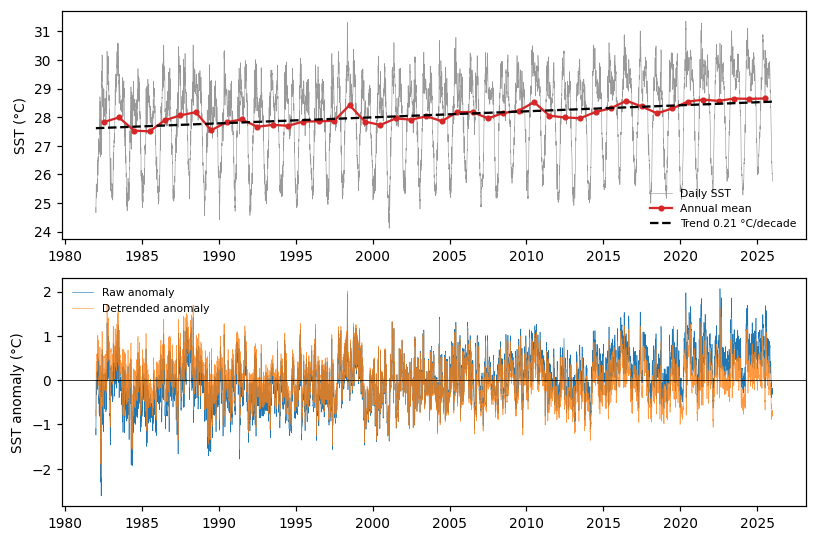

In [9]:
ann = df.sst.groupby(df.index.year).mean()
lr  = stats.linregress(ann.index, ann.values)
lrd = stats.linregress(np.arange(len(df)) / 3652.5, df.sst.values)
print(f'SST trend: {lrd.slope:.2f} degC/decade (daily), {lr.slope*10:.3f} degC/decade (annual means, p = {lr.pvalue:.1e})')

mid = pd.to_datetime(ann.index.astype(str) + '-07-01')
fig, ax = plt.subplots(2, 1, figsize=(7.5, 5))
ax[0].plot(df.index, df.sst, lw=0.4, color='0.6', label='Daily SST')
ax[0].plot(mid, ann.values, 'o-', ms=3, color='C3', label='Annual mean')
ax[0].plot(df.index, lrd.intercept + lrd.slope * np.arange(len(df)) / 3652.5, '--', color='k',
           label=f'Trend {lrd.slope:.2f} °C/decade')
#ax[0].plot(mid, lr.intercept + lr.slope * ann.index, '--', color='k', label=f'Trend {lr.slope*10:.2f} °C/decade')
ax[0].set_ylabel('SST (°C)'); ax[0].legend(loc='lower right', fontsize=7, frameon=False)
ax[1].plot(df.index, anom_raw, lw=0.4, color='C0', label='Raw anomaly')
ax[1].plot(df.index, anom_det, lw=0.4, color='C1', alpha=0.8, label='Detrended anomaly')
ax[1].axhline(0, color='k', lw=0.5); ax[1].set_ylabel('SST anomaly (°C)')
ax[1].legend(loc='upper left', fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(f'{FIG}/fig1_sst_series_trend.png')

P2-2 — Annual MHW statistics, raw vs detrended (Figure 2)

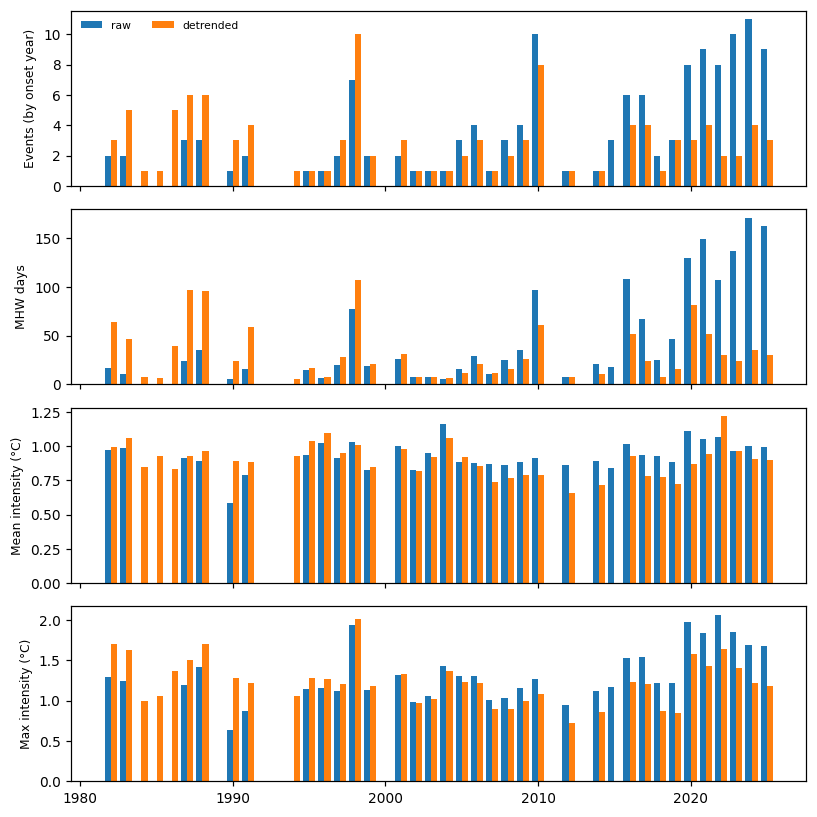

In [3]:
yrs = range(1982, 2026)
def annual(e, flag, anom):
    e, on = e.assign(year=pd.to_datetime(e.start).dt.year), flag == 1
    return pd.DataFrame({
        'events':   e.groupby('year').size().reindex(yrs, fill_value=0),
        'MHW days': flag.groupby(flag.index.year).sum().reindex(yrs).astype(int),
        'mean int': anom[on].groupby(anom[on].index.year).mean().reindex(yrs),
        'max int':  anom[on].groupby(anom[on].index.year).max().reindex(yrs)})
A = {'raw': annual(ev['raw'], df.mhw_raw, anom_raw),
     'detrended': annual(ev['detrended'], df.mhw_detrended, anom_det)}
pd.concat(A, axis=1).round(2).to_csv(f'{PROC}/p2_annual_mhw_stats.csv')

fig, ax = plt.subplots(4, 1, figsize=(7.5, 7.5), sharex=True)
for i, (col, lab) in enumerate([('events', 'Events (by onset year)'), ('MHW days', 'MHW days'),
                                ('mean int', 'Mean intensity (°C)'), ('max int', 'Max intensity (°C)')]):
    for j, (k, c) in enumerate([('raw', 'C0'), ('detrended', 'C1')]):
        ax[i].bar(np.array(yrs) + (j - 0.5) * 0.4, A[k][col], width=0.4, color=c, label=k)
    ax[i].set_ylabel(lab, fontsize=8)
ax[0].legend(fontsize=7, frameon=False, ncol=2)
fig.tight_layout(); fig.savefig(f'{FIG}/fig2_annual_mhw_stats.png')

P2-3 — Onset months and strong-event table (Figure 3)

start      1   2   3   4   5   6   7   8   9   10  11  12
raw         9   4  10  12  13  19   9   9  13  13  15   7
detrended   3   6   6  13  15  11  10  10  14   7   8   6
     start        end  duration  peak_date  i_max  i_mean  i_cum category
1987-11-16 1988-01-30        76 1987-11-26   1.50    0.99  74.95   Strong
1982-09-19 1982-11-07        50 1982-09-23   1.70    1.03  51.28   Strong
2020-06-25 2020-08-13        50 2020-07-29   1.14    0.78  38.92 Moderate
1991-02-23 1991-03-25        31 1991-03-11   1.09    0.93  28.78 Moderate
2021-05-03 2021-05-26        24 2021-05-21   1.43    1.13  27.04 Moderate
1998-05-05 1998-05-21        17 1998-05-13   2.01    1.50  25.49   Strong
2022-07-27 2022-08-12        17 2022-08-02   1.63    1.25  21.17   Strong
2001-04-03 2001-04-21        19 2001-04-07   1.33    0.98  18.67 Moderate
2023-04-24 2023-05-11        18 2023-05-01   1.40    1.02  18.30 Moderate
1988-02-12 1988-03-02        20 1988-02-29   1.35    0.90  18.07 Moderate
categories: 

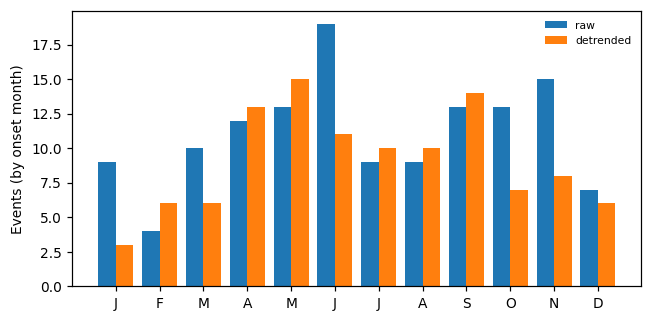

In [4]:
mon = pd.DataFrame({k: pd.to_datetime(e.start).dt.month.value_counts().reindex(range(1, 13), fill_value=0)
                    for k, e in ev.items()})
fig, ax = plt.subplots(figsize=(6, 3)); x = np.arange(1, 13)
ax.bar(x - 0.2, mon.raw, 0.4, label='raw', color='C0'); ax.bar(x + 0.2, mon.detrended, 0.4, label='detrended', color='C1')
ax.set_xticks(x, list('JFMAMJJASOND')); ax.set_ylabel('Events (by onset month)'); ax.legend(frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig(f'{FIG}/fig3_monthly_onsets.png')

for k, e in ev.items(): e.round(2).to_csv(f'{PROC}/p2_events_{k}.csv', index=False)
strong = ev['detrended'].sort_values('i_cum', ascending=False).head(10).round(2)
strong.to_csv(f'{PROC}/p2_strong_events_detrended.csv', index=False)
print(mon.T); print(strong.to_string(index=False))
print('categories:', ev['detrended'].category.value_counts().to_dict())

P2-4 — Onset composites: the gate (Figure 4)

109 onsets in composite
    variable  mean_days_m7_to_m1 sign  significant_days_before_onset
sst_anom_det                0.63    +                             30
     iobw_dt                0.62    +                             30
         t2m                0.58    +                             22
         shf                0.30    +                              9
        qnet                0.45    +                              8
         lhf                0.34    +                              8
        wspd               -0.38    -                              5
       swnet                0.39    +                              5
         u10               -0.10    -                              3
       lwnet               -0.09    -                              2
         v10               -0.06    -                              1
         dmi                0.12    +                              0
      nino34                0.18    +                              0
        rm

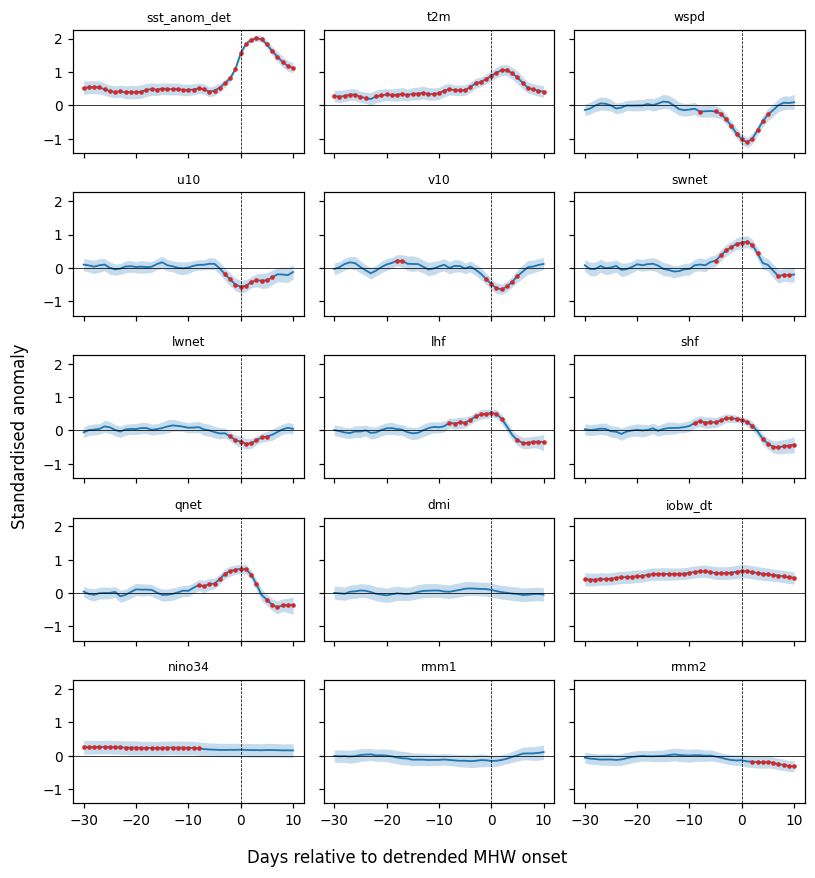

In [5]:
PRED = ['t2m','wspd','u10','v10','swnet','lwnet','lhf','shf','qnet','dmi','iobw_dt','nino34','rmm1','rmm2']
ERA  = PRED[:9]
def deseason(s):                                   # 1982-2021 day-of-year climatology, 31-day smoothed, then detrended
    base = s[s.index.year <= 2021]
    c = base.groupby(doy366(base.index)).mean()
    c = pd.Series(np.convolve(np.r_[c.values[-15:], c.values, c.values[:15]], np.ones(31) / 31, 'valid'), index=c.index)
    a = s - c.reindex(doy366(s.index)).values
    t = np.arange(len(a))
    return a - np.polyval(np.polyfit(t, a.values, 1), t)
X = pd.DataFrame({'sst_anom_det': anom_det})
for v in PRED: X[v] = deseason(df[v]) if v in ERA else df[v]
Z = (X - X.mean()) / X.std()                       # standardised, comparable across variables

L   = np.arange(-30, 11)
pos = [df.index.get_loc(d) for d in pd.to_datetime(ev['detrended'].start)]
on  = [i for i in pos if i + L[0] >= 0 and i + L[-1] < len(df)]
cube = np.stack([Z.values[i + L] for i in on])     # events x days x variables
rng  = np.random.default_rng(0)
boot = np.stack([cube[rng.integers(0, len(on), len(on))].mean(0) for _ in range(2000)])
mean, lo, hi = cube.mean(0), np.percentile(boot, 2.5, 0), np.percentile(boot, 97.5, 0)
sig = (lo > 0) | (hi < 0)

rows, k0 = [], np.where(L == -1)[0][0]
for j, v in enumerate(Z.columns):
    lead = 0
    while k0 - lead >= 0 and sig[k0 - lead, j] and np.sign(mean[k0 - lead, j]) == np.sign(mean[k0, j]):
        lead += 1
    rows.append(dict(variable=v, mean_days_m7_to_m1=mean[(L >= -7) & (L <= -1), j].mean(),
                     sign='+' if mean[k0, j] > 0 else '-', significant_days_before_onset=lead))
lead_table = pd.DataFrame(rows).sort_values('significant_days_before_onset', ascending=False).round(2)
lead_table.to_csv(f'{PROC}/p2_onset_lead_table.csv', index=False)
print(len(on), 'onsets in composite'); print(lead_table.to_string(index=False))

fig, axs = plt.subplots(5, 3, figsize=(7.5, 8), sharex=True, sharey=True)
for j, (v, ax) in enumerate(zip(Z.columns, axs.ravel())):
    ax.fill_between(L, lo[:, j], hi[:, j], color='C0', alpha=0.25, lw=0)
    ax.plot(L, mean[:, j], color='C0', lw=1.2)
    ax.plot(L[sig[:, j]], mean[sig[:, j], j], 'o', ms=2, color='C3')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5, ls='--'); ax.set_title(v, fontsize=8)
fig.supxlabel('Days relative to detrended MHW onset'); fig.supylabel('Standardised anomaly')
fig.tight_layout(); fig.savefig(f'{FIG}/fig4_onset_composites.png')

P2-5 — Spatial coherence map (Figure 5)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['/content/drive/MyDrive/MHW/mhw_check/oisst_box_grid.nc']
('time', 'lat', 'lon') (16071, 32, 32) | ocean cells: 805


/tmp/ipykernel_1494/1331860817.py:21: RuntimeWarning: Mean of empty slice
  clim = np.stack([np.nanmean(arr[(d == k) & base], 0) if k != 60 else np.full(arr.shape[1:], np.nan)
/tmp/ipykernel_1494/1331860817.py:27: RuntimeWarning: Mean of empty slice
  a = a - np.nanmean(a, 0)


median r = 0.73 | r >= 0.7: 62% | r < 0.5: 0% | min r = 0.47


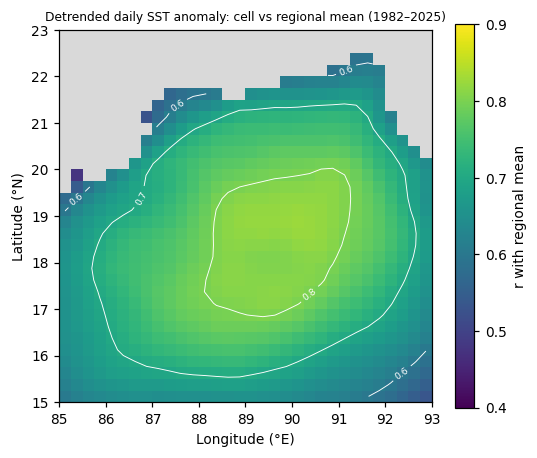

In [10]:
from google.colab import drive; drive.mount('/content/drive')
import glob, os, numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d
PROC = '/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/processed'
FIG  = f'{PROC}/figures'; os.makedirs(FIG, exist_ok=True)

hits = glob.glob('/content/drive/MyDrive/**/oisst_box_grid.nc', recursive=True)
print(hits)
ds  = xr.open_dataset(hits[0])
ds  = ds.rename({k: v for k, v in {'latitude': 'lat', 'longitude': 'lon'}.items() if k in ds.dims})
sst = (ds['sst'] if 'sst' in ds else ds[list(ds.data_vars)[0]]).squeeze(drop=True)
sst = sst.sel(time=slice('1982-01-01', '2025-12-31')).sortby('lat').load()
arr = sst.values.astype('float64')                                    # time x lat x lon
ocean = np.isfinite(arr).all(0)
print(sst.dims, arr.shape, '| ocean cells:', int(ocean.sum()))      # expect (16071, 32, 32) and 805

# per-cell anomaly: 1982-2021 day-of-year climatology (31-day smoothed), then linear detrend
tix = pd.DatetimeIndex(sst.time.values)
d   = tix.dayofyear.values.copy(); d[(~tix.is_leap_year) & (tix.month > 2)] += 1
base = tix.year <= 2021
clim = np.stack([np.nanmean(arr[(d == k) & base], 0) if k != 60 else np.full(arr.shape[1:], np.nan)
                 for k in range(1, 367)])
clim[59] = (clim[58] + clim[60]) / 2
clim = uniform_filter1d(clim, 31, axis=0, mode='wrap')
a = arr - clim[d - 1]
t = np.arange(len(a)) - (len(a) - 1) / 2
a = a - np.nanmean(a, 0)
a = a - t[:, None, None] * (np.nansum(a * t[:, None, None], 0) / np.sum(t ** 2))

# regional mean (cos-lat weighted, ocean only) and correlation of every cell with it
w   = np.cos(np.deg2rad(sst.lat.values))[:, None] * ocean
reg = np.nansum(a * w, axis=(1, 2)) / w.sum()
rz  = (reg - reg.mean()) / reg.std()
az  = (a - a.mean(0)) / a.std(0)
r   = np.full(ocean.shape, np.nan)
r[ocean] = (az[:, ocean] * rz[:, None]).mean(0)

rv = r[ocean]
print(f'median r = {np.median(rv):.2f} | r >= 0.7: {np.mean(rv >= 0.7):.0%} | '
      f'r < 0.5: {np.mean(rv < 0.5):.0%} | min r = {rv.min():.2f}')

cm = plt.get_cmap('viridis').copy(); cm.set_bad('0.85')              # land in grey
fig, ax = plt.subplots(figsize=(5, 4.2))
pc = ax.pcolormesh(sst.lon, sst.lat, np.ma.masked_invalid(r), cmap=cm, vmin=0.4, vmax=0.9, shading='nearest')
cs = ax.contour(sst.lon, sst.lat, np.ma.masked_invalid(r), levels=[0.6, 0.7, 0.8], colors='w', linewidths=0.6)
ax.clabel(cs, fmt='%.1f', fontsize=6)
fig.colorbar(pc, ax=ax, label='r with regional mean')
ax.set_xlabel('Longitude (°E)'); ax.set_ylabel('Latitude (°N)'); ax.set_aspect('equal')
ax.set_title('Detrended daily SST anomaly: cell vs regional mean (1982–2025)', fontsize=8)
fig.tight_layout(); fig.savefig(f'{FIG}/fig5_spatial_coherence.png', dpi=300)
xr.DataArray(r, coords={'lat': sst.lat, 'lon': sst.lon}, name='r').to_netcdf(f'{PROC}/p2_coherence_r.nc')